In [ ]:
import numpy as np
#np.random.seed(42)
p=0.30
sample_size=20
samples=np.random.binomial(n=1,p=p,size=sample_size)
print(samples)
#print(np.mean(samples)

[1 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 1 0 0]


In [ ]:
number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)
print("clicks",number_of_clicks)
print("non clicks",number_of_non_clicks)


clicks 7
non clicks 13


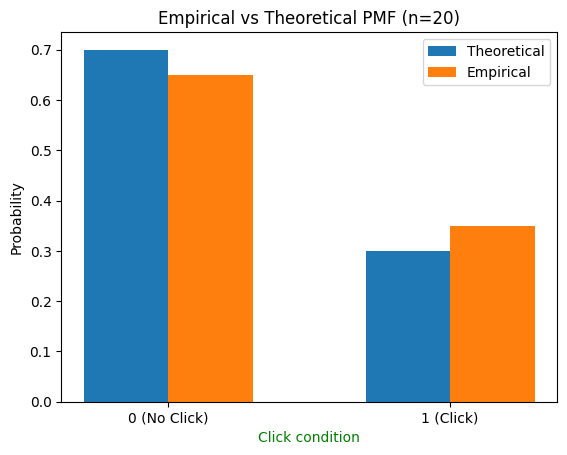

In [ ]:
import matplotlib.pyplot as plt
x_vals = [0, 1]
theoretical_pmf = [0.70, 0.30]
empirical_pmf = [number_of_non_clicks / sample_size, number_of_clicks / sample_size]
plt.bar(
    [x - 0.15 for x in x_vals],
    theoretical_pmf,
    width=0.3,
    label="Theoretical",
    align="center",
)
plt.bar(
    [x + 0.15 for x in x_vals],
    empirical_pmf,
    width=0.3,
    label="Empirical",
    align="center",
)
plt.xticks(x_vals, ["0 (No Click)", "1 (Click)"])
plt.xlabel("Click condition",color="green")
plt.ylabel("Probability")
plt.title("Empirical vs Theoretical PMF (n=20)")
plt.legend()
plt.show()

In [ ]:
sizes = [10, 100, 1000, 10000]
#np.random.seed(42)
for n in sizes:
    sim = np.random.binomial(n=1, p=0.30, size=n)
    px0 = np.mean(sim == 0)
    px1 = np.mean(sim == 1)
    mean = np.mean(sim)
    var = np.var(sim)
    print(f"{n:6d} | {px0:.4f} | {px1:.4f} | {mean:.4f} | {var:.4f}")

    10 | 1.0000 | 0.0000 | 0.0000 | 0.0000
   100 | 0.7000 | 0.3000 | 0.3000 | 0.2100
  1000 | 0.6930 | 0.3070 | 0.3070 | 0.2128
 10000 | 0.7026 | 0.2974 | 0.2974 | 0.2090


In [ ]:
import numpy as np
np.random.seed(42)
transactions=50
p_flag=0.04
n_simulation=20000
max_capacity=4
X = np.random.binomial(n=transactions, p=p_flag, size=n_simulation)
prob_exceed_capacity = np.mean(X > max_capacity)
unexamined_transactions = np.maximum(0, X - max_capacity)
total_unexamined = np.sum(unexamined_transactions)
avg_unexamined = np.mean(unexamined_transactions)

In [ ]:
print(f"Simulated mean flagged transactions per hour: {np.mean(X):.4f}")
print(f"Theoretical mean: {transactions * p_flag}")
print(f"Probability that capacity is exceeded (X > 4): {prob_exceed_capacity:.4f}")
print(f"Total unexamined flagged transactions: {total_unexamined}")
print(f"Average unexamined flagged transactions per hour: {avg_unexamined:.4f}")

Simulated mean flagged transactions per hour: 1.9987
Theoretical mean: 2.0
Probability that capacity is exceeded (X > 4): 0.0484
Total unexamined flagged transactions: 1353
Average unexamined flagged transactions per hour: 0.0677


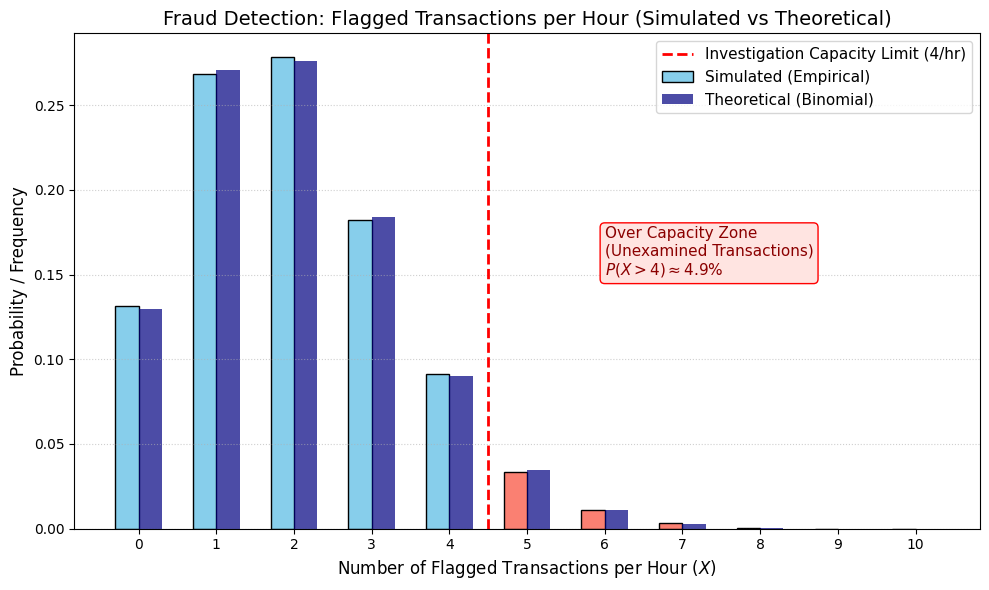

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom
n = 50
p = 0.04
simulations = 20000
max_capacity = 4
np.random.seed(42)
simulated_counts = np.random.binomial(n=n, p=p, size=simulations)
x_vals = np.arange(0, 11)
theoretical_pmf = binom.pmf(x_vals, n, p)
unique, counts = np.unique(simulated_counts, return_counts=True)
empirical_pmf_dict = dict(zip(unique, counts / simulations))
empirical_pmf = [empirical_pmf_dict.get(x, 0) for x in x_vals]
plt.figure(figsize=(10, 6))

bars = plt.bar(
    x_vals - 0.15,
    empirical_pmf,
    width=0.3,
    label="Simulated (Empirical)",
    color="skyblue",
    edgecolor="black",
)
for i, x in enumerate(x_vals):
    if x > max_capacity:
        bars[i].set_color("salmon")
        bars[i].set_edgecolor("black")
plt.bar(
    x_vals + 0.15,
    theoretical_pmf,
    width=0.3,
    label="Theoretical (Binomial)",
    color="navy",
    alpha=0.7,
)
plt.axvline(
    x=max_capacity + 0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Investigation Capacity Limit ({max_capacity}/hr)",
)
plt.xlabel("Number of Flagged Transactions per Hour ($X$)", fontsize=12)
plt.ylabel("Probability / Frequency", fontsize=12)
plt.title(
    "Fraud Detection: Flagged Transactions per Hour (Simulated vs Theoretical)",
    fontsize=14,
)
plt.xticks(x_vals)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.text(
    6,
    0.15,
    "Over Capacity Zone\n(Unexamined Transactions)\n$P(X > 4) \\approx 4.9\\%$",
    color="darkred",
    fontsize=11,
    bbox=dict(boxstyle="round", facecolor="mistyrose", edgecolor="red"),
)

plt.tight_layout()
plt.show()